In [37]:
import numpy as np
from IPython.display import clear_output
import random
import matplotlib.pyplot as plt
import time

In [2]:
def playmove(b,i,j,a):
    b[j[i],i] = a
    j[i] += 1
    return b,j,a*-1

In [3]:
def validmove(i,j):
    if (i < wid):
        if (j[i] < hei) :
            return True

    return False

In [4]:
def check4(b,i,j):
    if j < wid-3:
        if abs(sum(b[i,j:j+4])) == 4:
            return True
    if i < hei-3:
        if abs(sum(b[i:i+4,j])) == 4:
            return True       
    if i < hei-3 and j < wid-3:
        if abs(np.sum(b[i:i+4, j:j+4].diagonal())) == 4:
            return True
    if i >= 3 and j < wid-3:
        if abs(np.sum(np.fliplr(b[i-3:i+1, j:j+4]).diagonal())) == 4:
            return True
    return False

In [5]:
def checkboard(b):
    for j in range(wid):
        for i in range(hei):
            if board[i,j] == 0:
                break
            if check4(b,i,j):
                return True
    return False

In [31]:
def display():
    fig, ax = plt.subplots()

    ax.imshow(board[::-1], cmap='bwr', vmin=-1, vmax=1)

    ax.set_xticks(np.arange(-0.5, wid, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, hei, 1), minor=True)
    ax.set_yticks([])

    ax.grid(which='minor', color='black', linewidth=1)
    ax.tick_params(which='minor', bottom=False, left=False)
    plt.show()

In [66]:
def getmove(p):
    if p == 1:
        return int(input("Enter move"))
    if p == 2:
        return rand()
    if p == 3:
        return rec1(board,top,active,4)[1]

In [67]:
def rand():
    return random.randint(0,wid)

In [68]:
def evaluate(b, player):
    score = 0

    for i in range(hei):
        for j in range(wid):
            for di,dj in [(0,1),(1,0),(1,1),(-1,1)]:
                cells = []

                for k in range(4):
                    r = i + k*di
                    c = j + k*dj

                    if 0 <= r < hei and 0 <= c < wid:
                        cells.append(b[r,c])

                if len(cells) == 4:
                    own = cells.count(player)
                    opp = cells.count(-player)
                    empty = cells.count(0)

                    if own == 3 and empty == 1:
                        score += 10
                    elif own == 2 and empty == 2:
                        score += 3

                    if opp == 3 and empty == 1:
                        score -= 10
                    elif opp == 2 and empty == 2:
                        score -= 3

    return score

In [69]:
def rec1(b, t, player, depth):
    if depth == 0 or (sum(t) >= hei*wid):
        return evaluate(b,player), None

    best = -float('inf')
    move = None

    for i in range(wid):
        if t[i] < hei:
            j = t[i]

            b[j,i] = player
            t[i] += 1

            if check4(b,j,i):
                score = 100+depth

            else:
                score = -rec1(b,t,-player,depth-1)[0]

            b[j,i] = 0
            t[i] -= 1

            if score > best:
                best = score
                move = i

    return best, move

In [72]:
def rec1(b, t, player, depth):
    if depth == 0 or sum(t) >= hei*wid:
        return evaluate(b, player), None

    best = -float('inf')
    move = None

    for i in range(wid):
        if t[i] < hei:
            j = t[i]

            b[j,i] = player
            t[i] += 1

            if check4(b,j,i):
                score = 100 + depth
            else:
                score = -rec1(b,t,-player,depth-1)[0]

            b[j,i] = 0
            t[i] -= 1

            if score > best:
                best = score
                move = i

    if move is None:
        return 0, None

    return best, move

In [70]:
#Settings
wid = 9
hei = 7
#1 = Human
#2 = Random
p1 = 2
p2 = 3

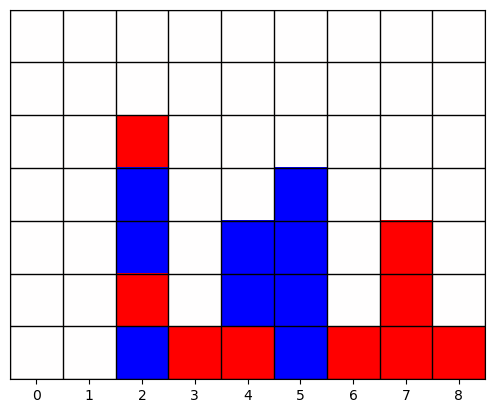

In [73]:
board = np.zeros((hei,wid),int)
top=np.zeros(wid,int)
active = 1
display()
while (sum(top) < hei*wid) and checkboard(board) == False:
    if active == 1:
        move = getmove(p1)
    else:
        move = getmove(p2)
    print(move)
    if validmove(move,top):
        board, top, active = playmove(board, move, top, active)
        time.sleep(0.5)
    else:
        print("Invalid Move")
    clear_output()
    display()
    

In [62]:
rec2(board,top,1,1)

10.11111111111111